# Hotel reviews: filtering, VADER sentiment, and clustering

This notebook processes the entire hotel dataset, saves the filtered and
scored CSVs locally, and investigates sentiment clusters. It retains
negation and punctuation for VADER after testing the lesson's proposed
stopword removal. Results are descriptive, not a validated recommender.

In [1]:
import ast
from collections import Counter
from pathlib import Path
import time
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from IPython.display import display
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

nltk.data.path.insert(0, str(Path('../data/nltk_data').resolve()))
df = pd.read_csv('../data/Hotel_Reviews.csv.gz')
assert df.shape == (515738, 17)
key = ['Hotel_Name', 'Hotel_Address']
df['Hotel_ID'] = df.groupby(key).ngroup()
df['Total_Number_of_Reviews'] = df.groupby(key).Reviewer_Score.transform('size')
df['Average_Score'] = df.groupby(key).Reviewer_Score.transform('mean').round(1)
# Assign the ID before shortening addresses so distinct properties cannot merge.
print('Distinct properties:', df.Hotel_ID.nunique())

Distinct properties: 1494


In [2]:
city_rules = {
    'Netherlands': 'Amsterdam, Netherlands', 'Spain': 'Barcelona, Spain',
    'United Kingdom': 'London, United Kingdom', 'Italy': 'Milan, Italy',
    'France': 'Paris, France', 'Austria': 'Vienna, Austria',
}
def shorten_address(address):
    for country, city in city_rules.items():
        if address.endswith(country):
            return city
    raise ValueError(f'Unexpected hotel country: {address}')

assert shorten_address('Street 1 Vienna Austria') == 'Vienna, Austria'
try:
    shorten_address('Unknown Country')
except ValueError:
    pass
else:
    raise AssertionError('Unknown countries must not silently become missing data')
address_map = {address: shorten_address(address) for address in df.Hotel_Address.unique()}
df['Hotel_Address'] = df.Hotel_Address.map(address_map)
df['Reviewer_Nationality'] = df.Reviewer_Nationality.str.strip()
display(df.groupby('Hotel_Address').agg(reviews=('Hotel_ID', 'size'), hotels=('Hotel_ID', 'nunique')))
assert df.Hotel_Address.notna().all()
df = df.drop(columns=[
    'lat', 'lng', 'Additional_Number_of_Scoring', 'Review_Date', 'days_since_review',
    'Review_Total_Negative_Word_Counts', 'Review_Total_Positive_Word_Counts',
    'Total_Number_of_Reviews_Reviewer_Has_Given',
])

,reviews,hotels
Hotel_Address,,
"Amsterdam, Netherlands",57214,105
"Barcelona, Spain",60149,211
"London, United Kingdom",262301,400
"Milan, Italy",37207,162
"Paris, France",59928,458
"Vienna, Austria",38939,158


In [3]:
def parse_tags(value):
    tags = ast.literal_eval(value)
    if not isinstance(tags, list) or not all(isinstance(tag, str) for tag in tags):
        raise ValueError('Expected a list of text tags')
    return [tag.strip() for tag in tags]

assert parse_tags("[' Couple ', ' Stayed 2 nights ']") == ['Couple', 'Stayed 2 nights']
assert parse_tags("['Business trip', 'Room, with a view']")[1] == 'Room, with a view'
try:
    parse_tags("{'Couple': 1}")
except ValueError:
    pass
else:
    raise AssertionError('Malformed tag containers must be rejected')
# Parse each distinct serialized list once, using literals rather than eval.
tag_lookup = {value: parse_tags(value) for value in df.Tags.unique()}
tags = df.Tags.map(tag_lookup)
tag_counts = Counter(tag for row in tags for tag in row)
display(pd.Series(dict(tag_counts.most_common(20))).to_frame('occurrences'))
selected_tags = {
    'Leisure_trip': {'Leisure trip'}, 'Couple': {'Couple'},
    'Solo_traveler': {'Solo traveler'}, 'Business_trip': {'Business trip'},
    'Group': {'Group', 'Travelers with friends', 'Travellers with friends'},
    'Family_with_young_children': {'Family with young children'},
    'Family_with_older_children': {'Family with older children'},
    'With_a_pet': {'With a pet'},
}
for column, labels in selected_tags.items():
    df[column] = tags.map(lambda row: int(bool(labels.intersection(row)))).astype('int8')
df = df.drop(columns='Tags')
display(df[list(selected_tags)].sum().to_frame('reviews'))
assert set(np.unique(df[list(selected_tags)].to_numpy())) <= {0, 1}
df.to_csv('../data/Hotel_Reviews_Filtered.csv.gz', index=False, compression='gzip')
reloaded = pd.read_csv('../data/Hotel_Reviews_Filtered.csv.gz')
assert reloaded.shape == df.shape
df = reloaded
print('Saved and reloaded full filtered dataset:', df.shape)

,occurrences
Leisure trip,417778
Submitted from a mobile device,307640
Couple,252294
Stayed 1 night,193645
Stayed 2 nights,133937
Solo traveler,108545
Stayed 3 nights,95821
Business trip,82939
Group,65392
Family with young children,61015


,reviews
Leisure_trip,417778
Couple,252294
Solo_traveler,108545
Business_trip,82939
Group,67535
Family_with_young_children,61015
Family_with_older_children,26349
With_a_pet,1405


Saved and reloaded full filtered dataset: (515738, 17)


## Stopword removal experiment

Negators and intensifiers are informative to VADER. Measure the proposed
filtering on controlled examples and a timed sample, but score the original
review columns. The placeholder strings are not real reviews: explicitly
give them zero and separately track whether any text was provided.

In [4]:
analyzer = SentimentIntensityAnalyzer()
stop = set(stopwords.words('english'))
def without_stopwords(text):
    return ' '.join(word for word in text.split() if word.casefold() not in stop)

probes = ['good', 'not good', 'very good', 'No Negative', 'No Positive',
          'Of course I LOVED sleeping in a room with no heating.']
display(pd.DataFrame([
    {'text': text, 'filtered': without_stopwords(text),
     'raw_compound': analyzer.polarity_scores(text)['compound'],
     'filtered_compound': analyzer.polarity_scores(without_stopwords(text))['compound']}
    for text in probes
]))
assert analyzer.polarity_scores('not good')['compound'] < 0
assert analyzer.polarity_scores(without_stopwords('not good'))['compound'] > 0
sample = df.sample(1000, random_state=42)
started = time.perf_counter()
cleaned_sample = sample[['Negative_Review', 'Positive_Review']].map(without_stopwords)
print('Stopword removal seconds for 2,000 fields:', round(time.perf_counter() - started, 3))

,text,filtered,raw_compound,filtered_compound
0,good,good,0.4404,0.4404
1,not good,good,-0.3412,0.4404
2,very good,good,0.4927,0.4404
3,No Negative,Negative,-0.7096,-0.5719
4,No Positive,Positive,0.3400,0.5574
5,Of course I LOVED sleeping in a room with no h...,course LOVED sleeping room heating.,0.5319,0.6841


Stopword removal seconds for 2,000 fields: 0.004


In [5]:
def review_sentiment(text):
    text = text.strip()
    if not text or text in {'No Negative', 'No Positive'}:
        return 0.0
    return analyzer.polarity_scores(text)['compound']

assert review_sentiment(' No Negative ') == 0
assert review_sentiment('No Positive') == 0
assert review_sentiment('') == 0
assert review_sentiment('not good') < 0 < review_sentiment('excellent')
started = time.perf_counter()
unique_text = pd.unique(pd.concat([df.Negative_Review, df.Positive_Review], ignore_index=True))
scores = {text: review_sentiment(text) for text in unique_text}
df['Negative_Sentiment'] = df.Negative_Review.map(scores)
df['Positive_Sentiment'] = df.Positive_Review.map(scores)
negative_present = ~df.Negative_Review.str.strip().isin(['', 'No Negative'])
positive_present = ~df.Positive_Review.str.strip().isin(['', 'No Positive'])
df['Has_Review_Text'] = negative_present | positive_present
df['Combined_Sentiment'] = (df.Negative_Sentiment + df.Positive_Sentiment) / (negative_present.astype(int) + positive_present.astype(int)).replace(0, np.nan)
assert len(df) == 515738
assert df[['Negative_Sentiment', 'Positive_Sentiment']].apply(lambda column: column.between(-1, 1).all()).all()
assert df.loc[~df.Has_Review_Text, 'Combined_Sentiment'].isna().all()
print('Scored distinct fields:', len(scores), '| Seconds:', round(time.perf_counter() - started, 2))
correlations = df[['Negative_Sentiment', 'Positive_Sentiment', 'Combined_Sentiment', 'Reviewer_Score']].corr()
display(correlations)
print('Positive-labelled fields with negative sentiment:', int((positive_present & df.Positive_Sentiment.lt(-0.05)).sum()))
print('Negative-labelled fields with positive sentiment:', int((negative_present & df.Negative_Sentiment.gt(0.05)).sum()))

Scored distinct fields: 740542 | Seconds: 65.67


,Negative_Sentiment,Positive_Sentiment,Combined_Sentiment,Reviewer_Score
Negative_Sentiment,1.000000,0.130339,0.607553,0.247638
Positive_Sentiment,0.130339,1.000000,0.733447,0.412532
Combined_Sentiment,0.607553,0.733447,1.000000,0.494729
Reviewer_Score,0.247638,0.412532,0.494729,1.000000


Positive-labelled fields with negative sentiment: 6940
Negative-labelled fields with positive sentiment: 101827


Silhouette on fixed 2,000-row sample: 0.5009


,reviews,mean_negative,mean_positive,mean_rating
cluster,,,,
0,77434,0.542784,0.721914,8.498785
1,312642,-0.133101,0.759448,8.751681
2,125425,-0.139792,0.004384,7.442275


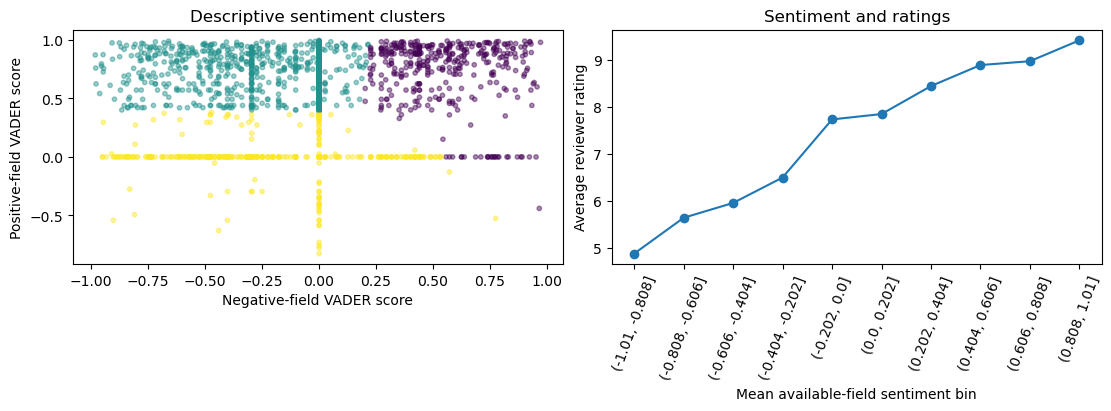

Saved full scored dataset: (515738, 22)


In [6]:
# Group by sentiment alone; use reviewer ratings only to describe the clusters.
present = df.loc[df.Has_Review_Text].copy()
features = ['Negative_Sentiment', 'Positive_Sentiment']
scaled = StandardScaler().fit_transform(present[features])
clusterer = KMeans(n_clusters=3, n_init=10, random_state=42)
present['cluster'] = clusterer.fit_predict(scaled)
print('Silhouette on fixed 2,000-row sample:', round(silhouette_score(scaled, present.cluster, sample_size=2000, random_state=42), 4))
summary = present.groupby('cluster').agg(
    reviews=('Hotel_ID', 'size'), mean_negative=('Negative_Sentiment', 'mean'),
    mean_positive=('Positive_Sentiment', 'mean'), mean_rating=('Reviewer_Score', 'mean'),
)
display(summary)
summary.to_csv('sentiment-clusters.csv')
df['Sentiment_Cluster'] = pd.Series(present.cluster, index=present.index).reindex(df.index).astype('Int64')
assert df.loc[~df.Has_Review_Text, 'Sentiment_Cluster'].isna().all()
plot = present.sample(2500, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].scatter(plot.Negative_Sentiment, plot.Positive_Sentiment, c=plot.cluster,
                cmap='viridis', alpha=0.45, s=10)
axes[0].set(xlabel='Negative-field VADER score', ylabel='Positive-field VADER score', title='Descriptive sentiment clusters')
bins = pd.cut(present.Combined_Sentiment, bins=np.linspace(-1.01, 1.01, 11))
rating_by_sentiment = present.groupby(bins, observed=True).Reviewer_Score.agg(['mean', 'size'])
axes[1].plot(range(len(rating_by_sentiment)), rating_by_sentiment['mean'], marker='o')
axes[1].set_xticks(range(len(rating_by_sentiment)), [str(value) for value in rating_by_sentiment.index], rotation=70)
axes[1].set(xlabel='Mean available-field sentiment bin', ylabel='Average reviewer rating', title='Sentiment and ratings')
fig.savefig('hotel-sentiment.png', dpi=160)
plt.show()
df.to_csv('../data/Hotel_Reviews_NLP.csv.gz', index=False, compression='gzip')
columns = pd.read_csv('../data/Hotel_Reviews_NLP.csv.gz', nrows=1).columns
assert 'Sentiment_Cluster' in columns and 'Combined_Sentiment' in columns
print('Saved full scored dataset:', df.shape)

## Challenge interpretation and limitations

K-Means groups reviews in two-dimensional sentiment space; the numbered
clusters have no intrinsic names or ordering. The table describes their
observed ratings without using those ratings to form the groups. Choosing
three clusters is an exploratory choice, and the sampled silhouette is not
evidence of real guest categories or future recommendation performance.

Higher combined sentiment may coincide with higher ratings, but neither the
correlation nor disagreement with a rating establishes sentiment accuracy.
Reviewers can praise one aspect and criticize another, and sarcasm remains
difficult. No-text rows are excluded from clustering rather than treated as
people who expressed neutral sentiment. The mean of available-field compound
scores is an explicitly simple summary, not a calibrated document score.

Removing *not* made a negative phrase positive in the executed experiment.
VADER therefore receives the intact text, with one cached score per exact
field. City and traveller tags remain available for later stratified
analysis; nationality is not a clustering feature. Repeated guests and
duplicate rows limit independence. The [movie-review assignment](assignment.ipynb)
tests a different domain with a real held-out split.